<a href="https://colab.research.google.com/github/sanchit-cmd/House-Price-Prediction/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [ ]:
df['total_rooms'] = np.log1p(df['total_rooms'])
df['total_bedrooms'] = np.log1p(df['total_bedrooms'])
df['population'] = np.log1p(df['population'])
df['households'] = np.log1p(df['households'])

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

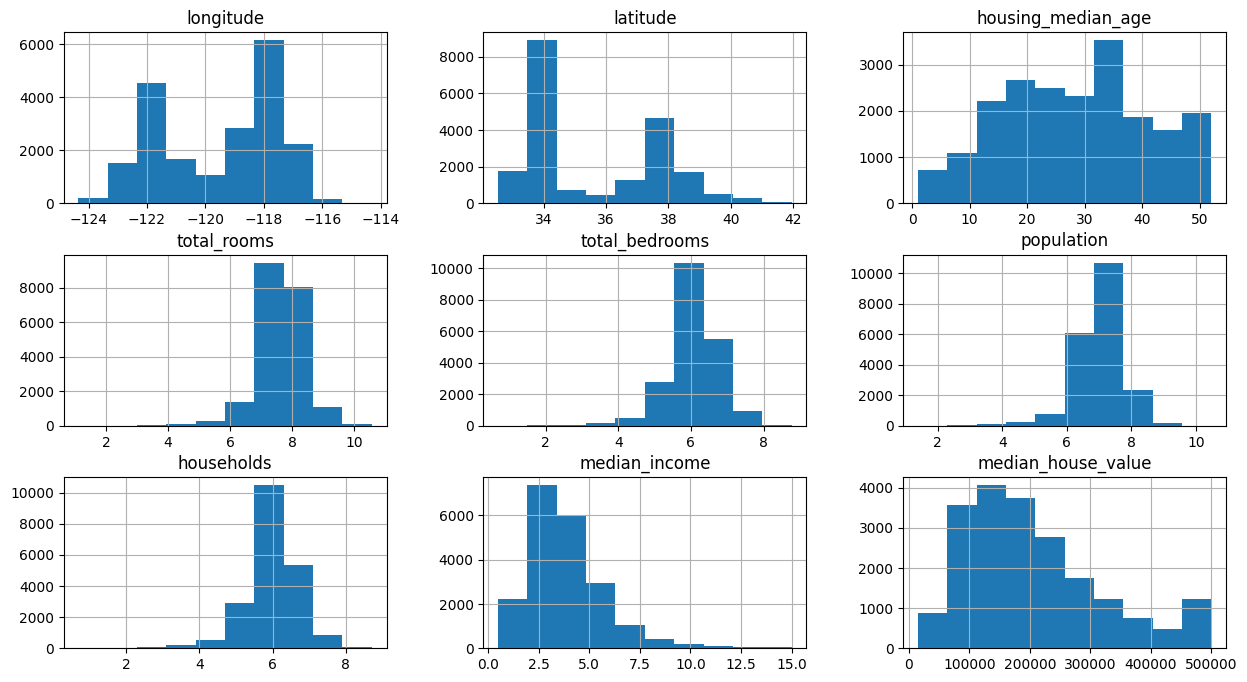

In [ ]:
df.hist(figsize=(15,8))

In [ ]:
if 'ocean_proximity' in df.columns:
    df = df.join(pd.get_dummies(df['ocean_proximity'], dtype=int)).drop('ocean_proximity', axis=1)

<Axes: >

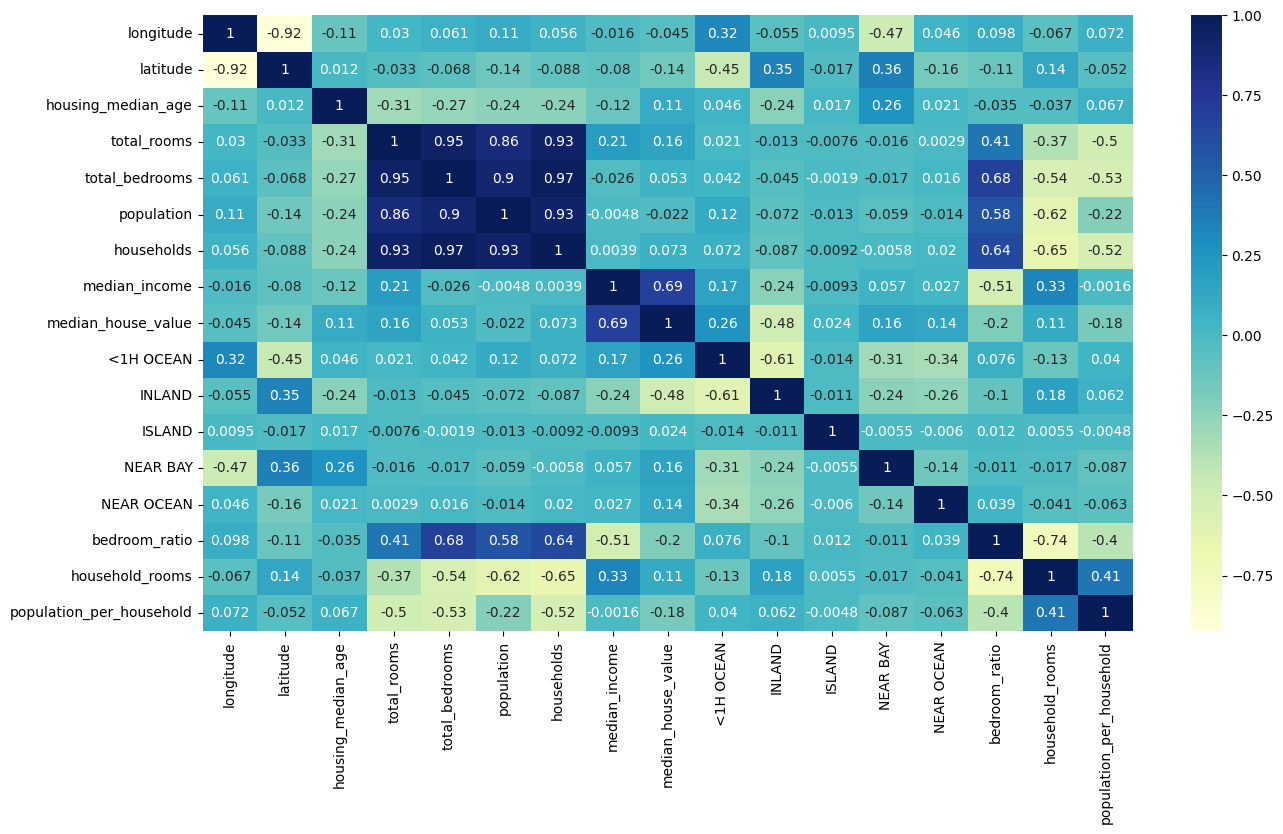

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="YlGnBu")

<Axes: xlabel='longitude', ylabel='latitude'>

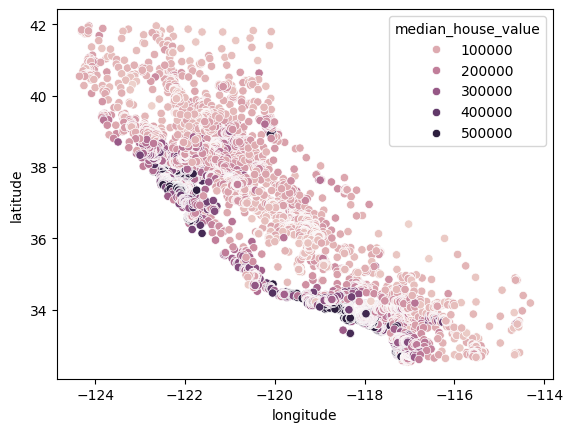

In [ ]:
sns.scatterplot(data=df, x='longitude', y='latitude', hue='median_house_value')

In [ ]:
df['bedroom_ratio'] = df['total_bedrooms'] / df['total_rooms']
df['household_rooms'] = df['total_rooms'] / df['households']
df['population_per_household'] = df['population'] / df['households']

<Axes: >

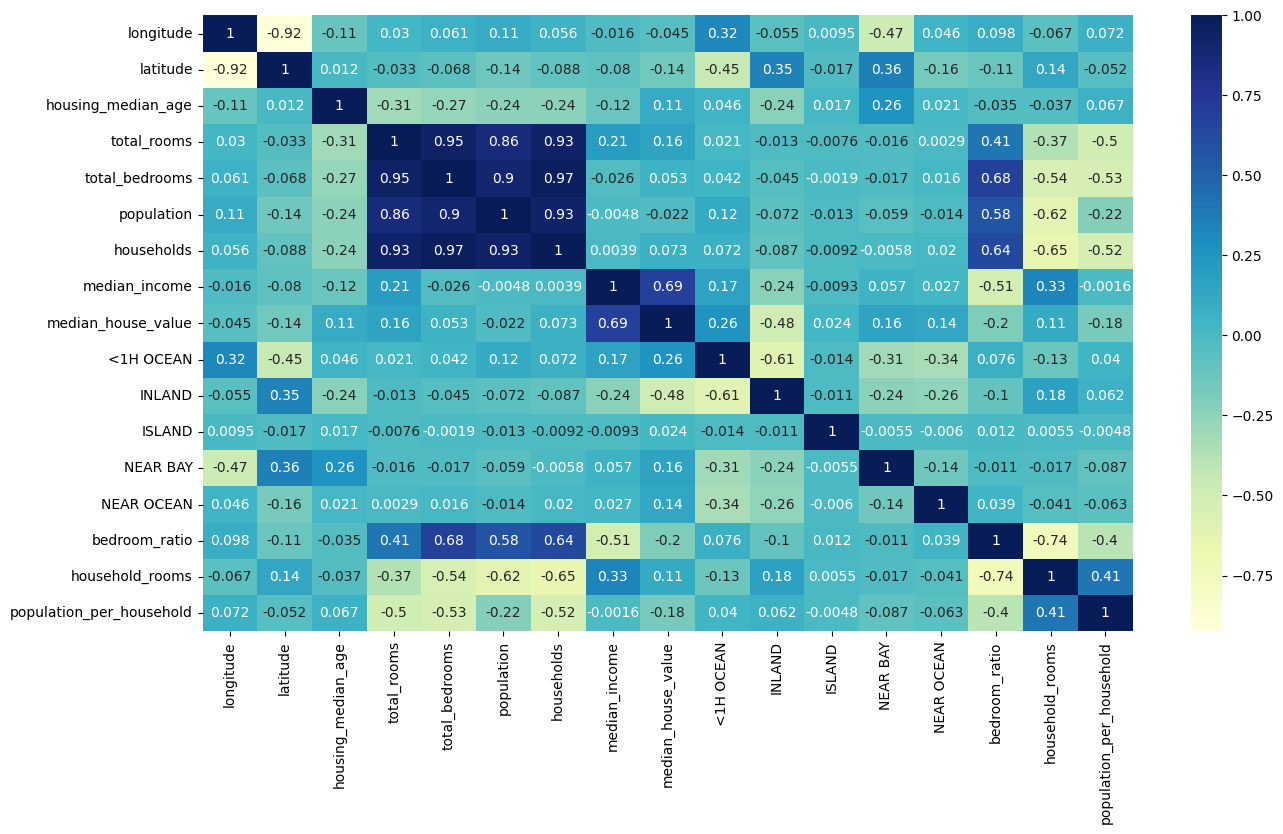

In [ ]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="YlGnBu")

In [ ]:
df.sample(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedroom_ratio,household_rooms,population_per_household
14439,-117.24,32.80,30.0,7.559038,6.137727,6.720220,6.082219,2.4671,276300.0,0,0,0,0,1,0.811972,1.242809,1.104896
1460,-121.99,37.97,22.0,7.945910,6.234411,7.148346,6.163315,5.1333,207200.0,0,1,0,0,0,0.784606,1.289227,1.159822
1163,-121.55,39.51,39.0,7.347300,5.869297,6.529419,5.739793,2.0357,57600.0,0,1,0,0,0,0.798837,1.280064,1.137570
1261,-121.72,38.00,7.0,8.981933,7.181592,8.403128,7.165493,4.9618,156500.0,0,1,0,0,0,0.799560,1.253498,1.172721
13702,-117.23,34.11,22.0,7.058758,5.402677,6.903747,5.501258,2.5875,81300.0,0,1,0,0,0,0.765386,1.283117,1.254940
19344,-122.87,38.62,18.0,7.909122,6.324359,7.419381,6.291569,3.1875,176100.0,1,0,0,0,0,0.799628,1.257099,1.179258
11687,-117.99,33.88,42.0,7.287561,5.713733,6.894670,5.752573,3.9559,161100.0,1,0,0,0,0,0.784039,1.266835,1.198537
11900,-117.37,33.94,14.0,9.136371,7.146772,8.179200,7.122060,6.6635,219600.0,0,1,0,0,0,0.782233,1.282827,1.148432
7455,-118.16,33.92,44.0,7.221836,5.627621,6.802395,5.605802,3.5938,161300.0,1,0,0,0,0,0.779251,1.288279,1.213456
1927,-121.09,38.68,15.0,8.560061,6.568078,7.575585,6.492240,4.7083,213300.0,0,1,0,0,0,0.767293,1.318507,1.166868


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

x = df.drop('median_house_value', axis=1)
y = df['median_house_value']

scaler = StandardScaler()
x = scaler.fit_transform(x)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
reg = LinearRegression()
reg.fit(x_train, y_train)

LinearRegression()

In [ ]:
reg.score(x_test, y_test)

0.6710714692701566

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(x_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
forest_reg.score(x_test, y_test)

0.8106126742066768

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define the hyperparameter grid
param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

# Initialize RandomizedSearchCV with 3-fold cross validation
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

# Fit the search model
random_search.fit(x_train, y_train)

# Retrieve the best model and parameters
best_forest = random_search.best_estimator_
print("Best Parameters Found:", random_search.best_params_)

Best Parameters Found: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}


In [ ]:
# Evaluate the tuned model on the test dataset
tuned_score = best_forest.score(x_test, y_test)
print(f"Tuned Random Forest Test R^2 Score: {tuned_score:.6f}")

Tuned Random Forest Test R^2 Score: 0.815444
